# 3

### Nota: 9.42

En este proyecto, debes desarrollar un sistema de clasificación multiclase utilizando Python para predecir el tipo de corte de los diamantes basándote en el dataset proporcionado (diamonds.csv). El objetivo es implementar y comparar al menos 5 modelos de clasificación diferentes: regresión logística, KNN, SVC, árbol de decisión y Random Forest. Deberás seguir un enfoque de aprendizaje supervisado y preprocesar los datos de forma adecuada para manejar los valores faltantes y las variables categóricas. ¡A por el nuevo reto!

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn as sk

work_dir = "../media/1_lab4/3/"
file_dir = "diamonds.csv"
path = work_dir + file_dir
seed = 112211

In [2]:
df = pd.read_csv(path)

In [3]:
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  str    
 2   color    53940 non-null  str    
 3   clarity  53940 non-null  str    
 4   depth    53939 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53939 non-null  float64
 8   y        53940 non-null  float64
 9   z        53930 non-null  float64
dtypes: float64(6), int64(1), str(3)
memory usage: 4.1 MB


In [6]:
df.isna().sum()

carat       0
cut         0
color       0
clarity     0
depth       1
table       0
price       0
x           1
y           0
z          10
dtype: int64

En depth, x, z hay valores nulos, como son númericas, se rellenan con la media.

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
carat,53940.0,0.797940,0.474011,0.2,0.40,0.70,1.04,5.01
depth,53939.0,61.749413,1.432633,43.0,61.00,61.80,62.50,79.00
table,53940.0,57.457184,2.234491,43.0,56.00,57.00,59.00,95.00
price,53940.0,3932.799722,3989.439738,326.0,950.00,2401.00,5324.25,18823.00
x,53939.0,5.731153,1.121771,0.0,4.71,5.70,6.54,10.74
y,53940.0,5.734526,1.142135,0.0,4.72,5.71,6.54,58.90
z,53930.0,3.538723,0.705762,0.0,2.91,3.53,4.04,31.80


In [8]:
df.describe(include = "O").T

/tmp/ipykernel_33779/3878929891.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include = "O").T


,count,unique,top,freq
cut,53940,5,Ideal,21551
color,53940,7,G,11292
clarity,53940,8,SI1,13065


Hacemos el preprocesamiento en un ColumnTransformer para que esté preparado para el pipeline

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, LabelEncoder

columnas_numericas = ["carat", "depth", "table", "price", "x", "y", "z"]
columnas_categoricas = ["color", "clarity"] 

preprocessor = ColumnTransformer(
    transformers=[
        # Numéricas: imputar nulos con la media y estandarizar
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="mean")),
            ("scaler", StandardScaler()),
        ]), columnas_numericas),

        # Categóricas: codificar como números enteros (equivalente a LabelEncoder)
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
         columnas_categoricas),
    ],
    remainder="drop",
).set_output(transform="pandas")   # devuelve un DataFrame con nombres de columna

Por separado modificamos la variable a predecir.

In [12]:
X = df.drop(columns="cut")

le = LabelEncoder()
y = le.fit_transform(df["cut"]) 

Ponemos los modelos

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = [
    LogisticRegression(max_iter=1000),
    KNeighborsClassifier(),
    SVC(),
    DecisionTreeClassifier(random_state=seed),
    RandomForestClassifier(random_state=seed),
]

Pipelines con los modelos + train test split

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report, f1_score

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=seed, stratify=y
)

t_models = {}
acc = {}
cm = {}
report = {}
f1 = {}

for model in models:
    print(f"Entrenando: {model}")
    clf = sk.pipeline.Pipeline(steps = [("preprocessor", preprocessor), ("classifier", model)])
    trained_model = clf.fit(X_train, y_train)
    t_models[model] = trained_model
    preds = trained_model.predict(X_test)
    acc[model] = accuracy_score(y_test, preds)
    print(f"Listo! Precisión: {acc[model]}\n")
    cm[model] = confusion_matrix(y_test, preds)
    report[model] = classification_report(y_test, preds, zero_division = 1)
    print(report[model])
    f1[model] = f1_score(y_test, preds, average = None)

Entrenando: LogisticRegression(max_iter=1000)
Listo! Precisión: 0.653596588802373

              precision    recall  f1-score   support

           0       0.78      0.51      0.62       322
           1       0.58      0.15      0.24       981
           2       0.71      0.87      0.78      4310
           3       0.66      0.72      0.69      2758
           4       0.49      0.41      0.45      2417

    accuracy                           0.65     10788
   macro avg       0.64      0.53      0.55     10788
weighted avg       0.64      0.65      0.63     10788

Entrenando: KNeighborsClassifier()
Listo! Precisión: 0.6586948461253245

              precision    recall  f1-score   support

           0       0.84      0.67      0.75       322
           1       0.52      0.49      0.51       981
           2       0.76      0.90      0.83      4310
           3       0.61      0.70      0.66      2758
           4       0.43      0.24      0.30      2417

    accuracy                 

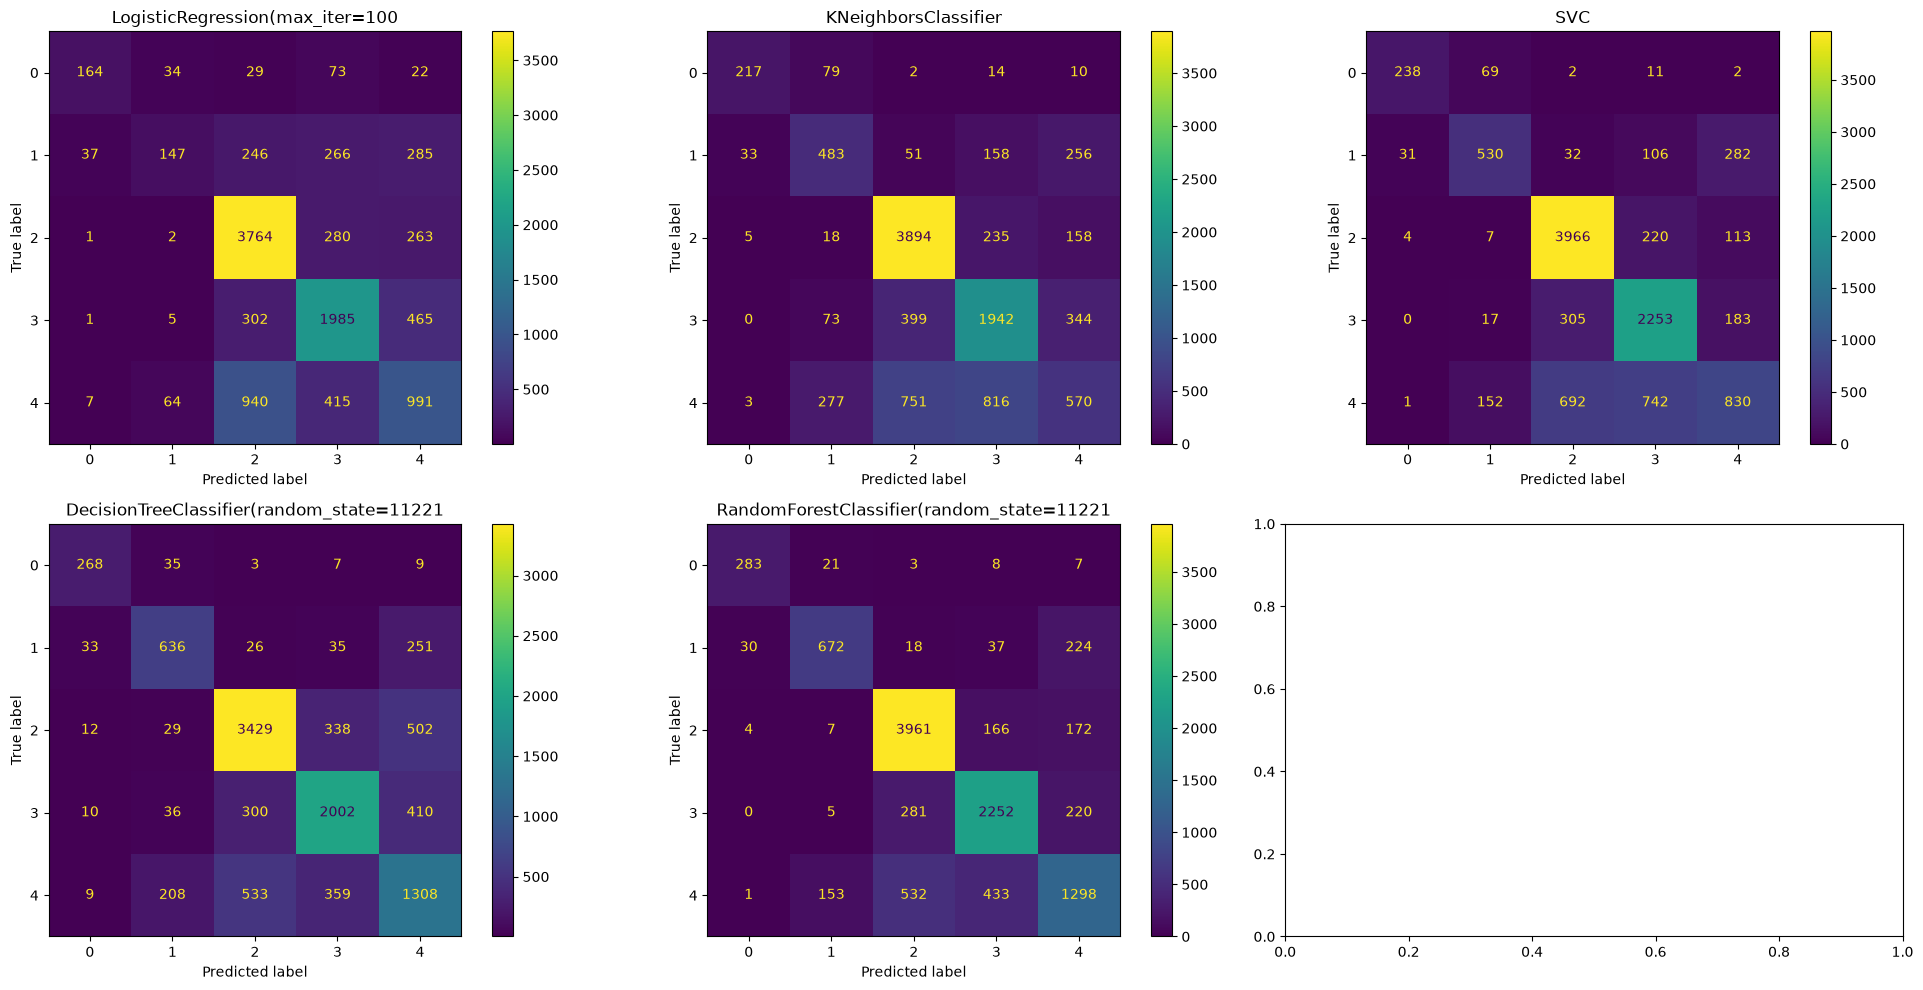

In [20]:
fig, axes = plt.subplots(nrows = 2, ncols = 3)
fig.set_figwidth(20)
fig.set_figheight(10)
ax_ = axes.flatten()

for model, ax in zip(models, ax_):
    ConfusionMatrixDisplay(cm[model]).plot(ax = ax)
    ax.set_title(str(model)[:-2])

plt.tight_layout()

El modelo que mejor rinde según el F1 score es el Random Forest, con un F1 macro de 0,78 y un F1 ponderado de 0,78, además de la mayor accuracy (0,785). Es el mejor en las cinco clases de cut, y supera en 7 puntos de F1 macro al segundo modelo (árbol de decisión, 0,71). Las clases más difíciles de predecir son Very Good y Good, en las que todos los modelos tienen los F1 más bajos, mientras que Fair e Ideal se identifican mejor. La regresión logística es el modelo con peor resultado (F1 macro de 0,55), con un rendimiento muy bajo en la clase Good. Se ha usado el F1 macro como criterio principal por el desbalanceo de clases, y el resultado es el mismo con el promedio ponderado.